# Urbane Luftverschmutzung: Cross Validation und Hyperparameter-Tuning (Gradient Boosting)

Zweiter Durchlauf von `lukas_gb_cv_tuning.ipynb`, diesmal mit **allen
verfügbaren Rohfeatures** (74 Spalten inklusive der Satelliten-Winkel- und
-Höhenspalten, dazu Tag im Jahr, Wochentag und Windgeschwindigkeit) statt nur
der 8 Baseline-Features. Es läuft weiterhin **vor dem Feature Engineering** (keine Aggregate)
und zeigt, ob das Tuning mit mehr Information mehr bewirkt.

Wegen der größeren Feature-Zahl dauert jeder Fit länger. Die Suche nutzt deshalb
30 statt 60 Konfigurationen, die verschachtelte Suche 10 statt 25.

**Ablauf**

1. Cross Validation mit Standardparametern als Referenz (Streuung zwischen den Folds ansehen).
2. Zufallssuche über einen Hyperparameter-Raum, bewertet per `GroupKFold` nach `Place_ID`.
3. **Verschachtelte Cross Validation** (Nested CV) als ehrliche Schätzung des getunten Modells.
4. Einfluss der Hyperparameter und Fehleranalyse.

**Wichtige Regeln**

- Train und Test enthalten **keine gemeinsamen Orte**, daher gruppiert jede Validierung nach `Place_ID`.
  Ein zufälliger Split würde Orte teilen und den Score zu optimistisch machen.
- Metrik ist RMSE (Vorgabe von Zindi), zusätzlich MAE und R².
- `target_min/max/variance/count` gibt es nur in Train (Leakage) und werden nicht verwendet.

In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("data")

## 1. Daten und Features (alle Rohfeatures)

In [2]:
train = pd.read_csv(DATA_DIR / "Train.csv", parse_dates=["Date"])

train["dayofyear"] = train["Date"].dt.day_of_year
train["weekday"] = train["Date"].dt.day_of_week
train["wind_speed"] = np.sqrt(train["u_component_of_wind_10m_above_ground"] ** 2
                              + train["v_component_of_wind_10m_above_ground"] ** 2)

meta_cols = ["Place_ID X Date", "Date", "Place_ID"]
# target_* gibt es nur in Train (Leakage) und wird ausgeschlossen
features = [c for c in train.columns
            if c not in meta_cols and not c.startswith("target")]
X, y, groups = train[features], train["target"], train["Place_ID"]
print(f"{len(features)} Features, {len(train)} Zeilen, {groups.nunique()} Orte")

77 Features, 30557 Zeilen, 340 Orte


## 2. Cross Validation mit Standardparametern

5-fach `GroupKFold`: Alle Zeilen eines Ortes liegen immer im Training **oder**
in der Validierung. Wir schauen neben dem Gesamtwert auch auf die Werte
je Fold, weil nur 340 Orte vorliegen und die Folds spürbar streuen.

In [3]:
outer_cv = GroupKFold(n_splits=5)
folds = list(outer_cv.split(X, y, groups))


def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


def cv_oof(params, cols=features):
    """Out-of-fold-Vorhersagen für eine Parameterkonfiguration."""
    oof = np.zeros(len(y))
    for tr, va in folds:
        m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **params)
        m.fit(X.iloc[tr][cols], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va][cols])
    return oof


def summarize(oof, name):
    fold = [rmse(y.iloc[va], oof[va]) for _, va in folds]
    return {"Modell": name, "RMSE": rmse(y, oof), "RMSE Fold-Std": np.std(fold),
            "RMSE Fold-Min": min(fold), "RMSE Fold-Max": max(fold),
            "MAE": mean_absolute_error(y, oof), "R²": r2_score(y, oof)}


oof_default = cv_oof({})
row_default = summarize(oof_default, "Standardparameter")
print("RMSE je Fold:", [round(rmse(y.iloc[va], oof_default[va]), 2) for _, va in folds])
pd.DataFrame([row_default]).set_index("Modell").round(2)

RMSE je Fold: [np.float64(31.23), np.float64(37.28), np.float64(32.08), np.float64(37.06), np.float64(27.18)]


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,33.19,3.81,27.18,37.28,22.91,0.5


### Welche Features nutzt das Standardmodell?

Permutation Importance auf den jeweiligen Validierungsfolds (Mittel über 5 Folds):
Ein Feature ist wichtig, wenn das Mischen seiner Werte den RMSE auf unbekannten
Orten erhöht.

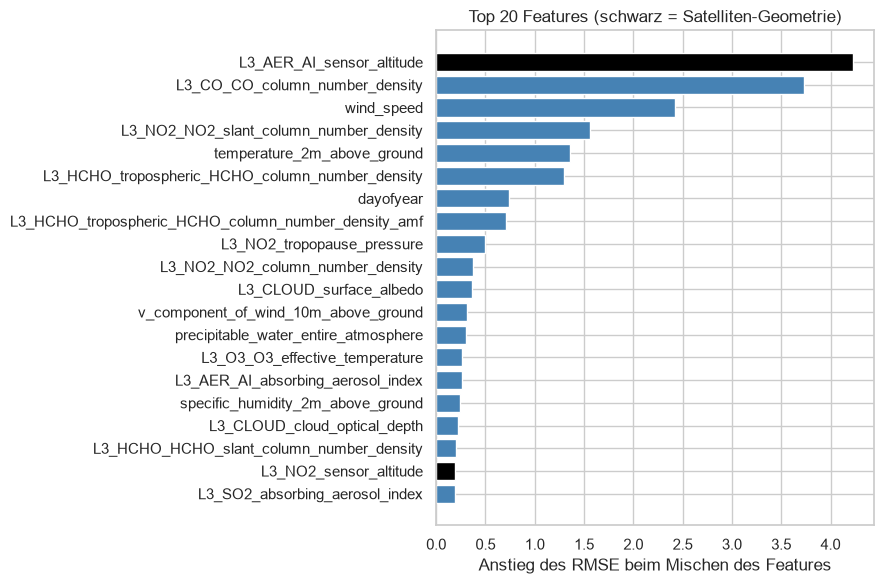

Anteil der Geometrie-Spalten an der gesamten Importance: 0.24 (35 von 77 Features)


In [4]:
from sklearn.inspection import permutation_importance

imps = []
for tr, va in folds:
    m = HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(m, X.iloc[va], y.iloc[va], n_repeats=3,
                                random_state=RANDOM_STATE, n_jobs=1,
                                scoring="neg_root_mean_squared_error")
    imps.append(pd.Series(pi.importances_mean, index=features))
imp_mean = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)

geom = ("sensor_azimuth", "sensor_zenith", "solar_azimuth", "solar_zenith", "sensor_altitude")
is_geom = imp_mean.index.to_series().apply(lambda c: any(g in c for g in geom))
top = imp_mean.head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index[::-1], top.values[::-1],
        color=["black" if is_geom[c] else "steelblue" for c in top.index[::-1]])
ax.set_xlabel("Anstieg des RMSE beim Mischen des Features")
ax.set_title("Top 20 Features (schwarz = Satelliten-Geometrie)")
plt.tight_layout()
plt.show()
pos = imp_mean.clip(lower=0)
print(f"Anteil der Geometrie-Spalten an der gesamten Importance: {pos[is_geom].sum() / pos.sum():.2f} "
      f"({int(is_geom.sum())} von {len(features)} Features)")

## 3. Hyperparameter-Tuning (Zufallssuche)

Wir durchsuchen die wichtigsten Stellschrauben von `HistGradientBoostingRegressor`:

| Parameter | Bereich | Wirkung |
| --- | --- | --- |
| `learning_rate` | 0,01 bis 0,3 (log) | Schrittweite pro Baum |
| `max_iter` | 100 bis 600 | Anzahl Bäume |
| `max_leaf_nodes` | 8 bis 64 | Komplexität eines Baums |
| `max_depth` | 3, 5, 8, unbegrenzt | zusätzliche Tiefenbegrenzung |
| `min_samples_leaf` | 20 bis 400 | Mindestgröße eines Blatts (gegen Überanpassung) |
| `l2_regularization` | 0,001 bis 10 (log) | Strafe auf große Blattwerte |
| `max_features` | 0,5, 0,7, 1,0 | Anteil der Features pro Baum |

Die Zufallssuche (statt eines vollständigen Gitters) deckt einen großen Raum mit
wenigen Fits ab. Bewertet wird mit `GroupKFold` nach Orten, Ziel ist der RMSE.

In [5]:
param_space = {
    "learning_rate": loguniform(0.01, 0.3),
    "max_iter": randint(100, 600),
    "max_leaf_nodes": randint(8, 64),
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": randint(20, 400),
    "l2_regularization": loguniform(1e-3, 10),
    "max_features": [0.5, 0.7, 1.0],
}


def make_search(n_iter, cv):
    return RandomizedSearchCV(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        param_space, n_iter=n_iter, cv=cv,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE, n_jobs=1, refit=False)


t0 = time.time()
search = make_search(30, GroupKFold(n_splits=5))
search.fit(X, y, groups=groups)
print(f"Suche fertig in {time.time() - t0:.0f} s")

res = pd.DataFrame(search.cv_results_)
res["rmse"] = -res["mean_test_score"]
res = res.sort_values("rmse").reset_index(drop=True)
param_cols = [f"param_{p}" for p in param_space]
res[param_cols + ["rmse", "std_test_score"]].head(8).round(3)

Suche fertig in 437 s


,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_max_depth,param_min_samples_leaf,param_l2_regularization,param_max_features,rmse,std_test_score
0,0.063,316,52,None,60,0.976,0.7,31.871,3.768
1,0.038,450,55,None,290,0.063,0.7,31.886,3.715
2,0.087,548,42,8,120,0.829,1.0,31.951,3.748
3,0.194,545,18,None,147,0.342,0.7,32.478,3.851
4,0.112,479,20,5,198,0.001,0.7,32.521,3.734
5,0.078,128,43,8,32,0.004,1.0,32.704,3.667
6,0.020,576,25,None,237,0.050,0.7,32.728,3.737
7,0.080,289,54,5,70,0.015,1.0,32.741,3.863


Die besten Werte der Suche sind **optimistisch**: Wir haben aus 30 Konfigurationen
die beste gewählt, und genau auf diesen Folds bewertet. Wir prüfen sie daher
zuerst per Cross Validation gegen die Standardparameter und danach in der
verschachtelten Validierung (Abschnitt 4).

In [6]:
best_params = {p: res.loc[0, f"param_{p}"] for p in param_space}
# NumPy-Typen und None in normale Python-Werte umwandeln
best_params = {k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
               for k, v in best_params.items()}
for k in ("max_iter", "max_leaf_nodes", "min_samples_leaf"):
    best_params[k] = int(best_params[k])
print(json.dumps(best_params, indent=2))

oof_tuned = cv_oof(best_params)
row_tuned = summarize(oof_tuned, "Getunt (beste Konfiguration)")
print("RMSE je Fold (getunt):", [round(rmse(y.iloc[va], oof_tuned[va]), 2) for _, va in folds])
print("RMSE je Fold (Standard):", [round(rmse(y.iloc[va], oof_default[va]), 2) for _, va in folds])
pd.DataFrame([row_default, row_tuned]).set_index("Modell").round(2)

{
  "learning_rate": 0.06268891016222734,
  "max_iter": 316,
  "max_leaf_nodes": 52,
  "max_depth": null,
  "min_samples_leaf": 60,
  "l2_regularization": 0.9756194291174574,
  "max_features": 0.7
}


RMSE je Fold (getunt): [np.float64(30.16), np.float64(36.18), np.float64(30.86), np.float64(35.93), np.float64(26.22)]
RMSE je Fold (Standard): [np.float64(31.23), np.float64(37.28), np.float64(32.08), np.float64(37.06), np.float64(27.18)]


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,33.19,3.81,27.18,37.28,22.91,0.50
Getunt (beste Konfiguration),32.10,3.77,26.22,36.18,21.85,0.53


## 4. Verschachtelte Cross Validation (ehrliche Schätzung)

Im äußeren Loop (5 Folds) liegt ein Teil der Orte komplett zurück. Im inneren
Loop sucht eine Zufallssuche (10 Konfigurationen, 3-fach `GroupKFold`) nur auf
den Trainingsorten die beste Konfiguration. Das so gewählte Modell wird erst
dann auf den zurückgelegten Orten bewertet. Der Wert zeigt, was das **Verfahren
„Tuning“** auf unbekannten Orten leistet, ohne dass die Validierungsorte
bei der Wahl der Parameter mitgewirkt haben.

In [7]:
t0 = time.time()
oof_nested = np.zeros(len(y))
nested_params = []
for i, (tr, va) in enumerate(folds):
    inner = make_search(10, GroupKFold(n_splits=3))
    inner.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
    p = inner.cv_results_["params"][int(np.argmin(inner.cv_results_["rank_test_score"]))]
    nested_params.append(p)
    m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **p).fit(X.iloc[tr], y.iloc[tr])
    oof_nested[va] = m.predict(X.iloc[va])
    print(f"Fold {i + 1}/5: RMSE {rmse(y.iloc[va], oof_nested[va]):.2f} "
          f"(Standard: {rmse(y.iloc[va], oof_default[va]):.2f}), {time.time() - t0:.0f} s")

row_nested = summarize(oof_nested, "Getunt (verschachtelt)")
pd.DataFrame(nested_params).round(3)

Fold 1/5: RMSE 31.14 (Standard: 31.23), 90 s


Fold 2/5: RMSE 37.21 (Standard: 37.28), 182 s


Fold 3/5: RMSE 31.70 (Standard: 32.08), 269 s


Fold 4/5: RMSE 36.51 (Standard: 37.06), 369 s


Fold 5/5: RMSE 27.08 (Standard: 27.18), 471 s


,l2_regularization,learning_rate,max_depth,max_features,max_iter,max_leaf_nodes,min_samples_leaf
0,0.05,0.02,None,0.7,576,25,237
1,0.05,0.02,None,0.7,576,25,237
2,0.05,0.02,None,0.7,576,25,237
3,0.05,0.02,None,0.7,576,25,237
4,0.05,0.02,None,0.7,576,25,237


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,33.19,3.81,27.18,37.28,22.91,0.50
Getunt (beste Konfiguration),32.10,3.77,26.22,36.18,21.85,0.53
Getunt (verschachtelt),32.94,3.74,27.08,37.21,22.72,0.51


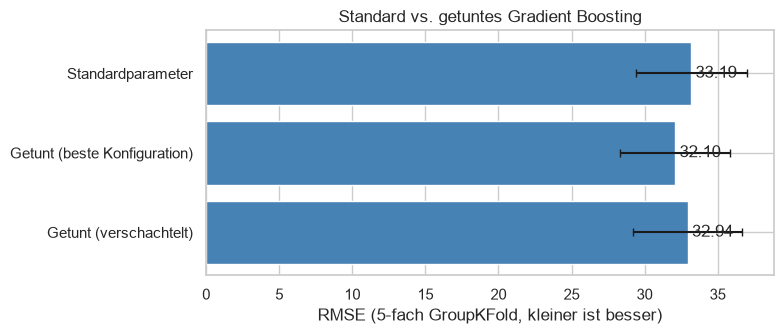

In [8]:
summary = pd.DataFrame([row_default, row_tuned, row_nested]).set_index("Modell")
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(summary.index[::-1], summary["RMSE"][::-1], color="steelblue",
        xerr=summary["RMSE Fold-Std"][::-1], capsize=3)
for i, v in enumerate(summary["RMSE"][::-1]):
    ax.text(v + 0.3, i, f"{v:.2f}", va="center")
ax.set_xlabel("RMSE (5-fach GroupKFold, kleiner ist besser)")
ax.set_title("Standard vs. getuntes Gradient Boosting")
plt.tight_layout()
plt.show()

## 5. Einfluss der Hyperparameter

Welche Parameter bestimmen den Score? Jeder Punkt ist eine der 30 Konfigurationen
der Zufallssuche (RMSE aus 5-fach `GroupKFold`).

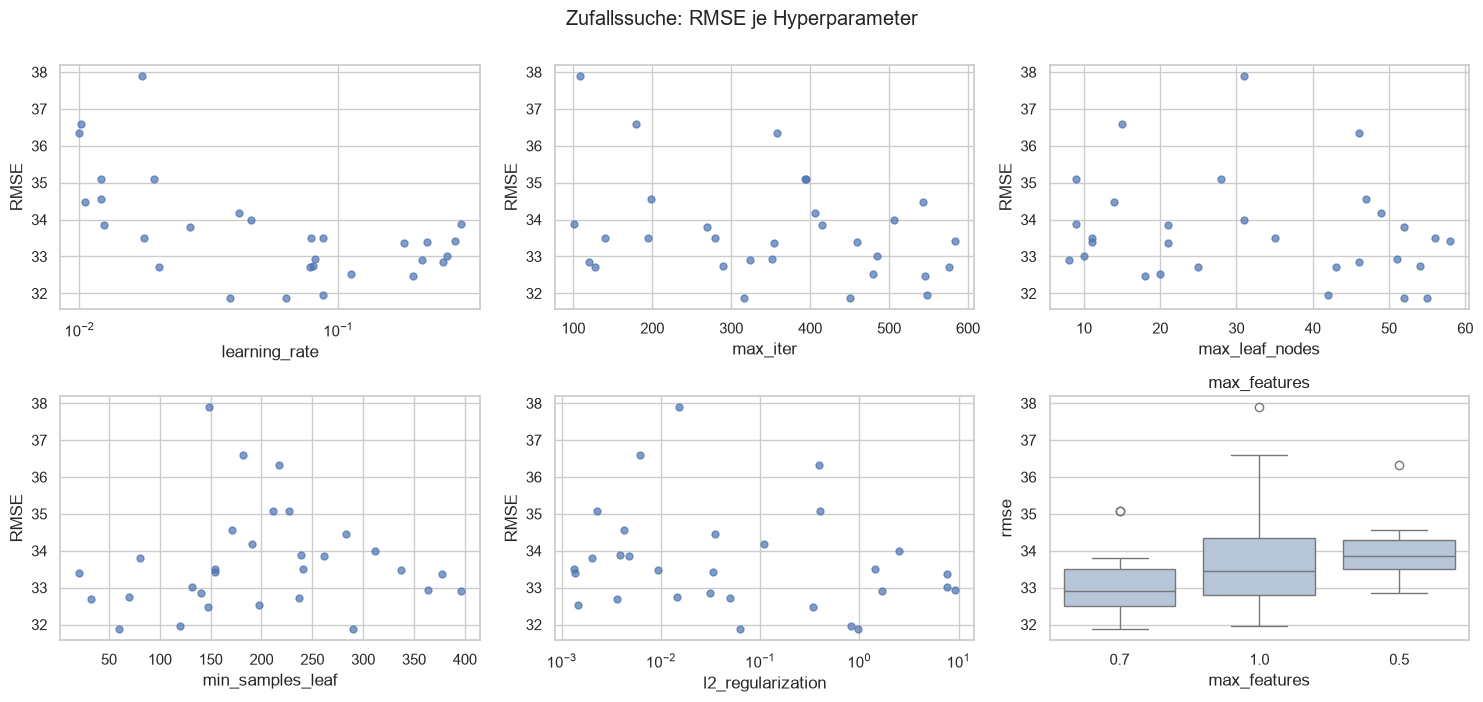

Spearman-Korrelation mit RMSE:
param_max_iter            -0.27
param_max_leaf_nodes      -0.21
param_min_samples_leaf     0.22
param_l2_regularization   -0.19
log_lr                    -0.57


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
plots = [("learning_rate", True), ("max_iter", False), ("max_leaf_nodes", False),
         ("min_samples_leaf", False), ("l2_regularization", True)]
for ax, (p, log) in zip(axes.ravel(), plots):
    ax.scatter(res[f"param_{p}"].astype(float), res["rmse"], s=25, alpha=0.7)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(p); ax.set_ylabel("RMSE")
cat = res.assign(max_depth=res["param_max_depth"].astype(str),
                 max_features=res["param_max_features"].astype(str))
sns.boxplot(data=cat, x="max_features", y="rmse", ax=axes[1, 2], color="lightsteelblue")
axes[1, 2].set_title("max_features")
plt.suptitle("Zufallssuche: RMSE je Hyperparameter", y=1.0)
plt.tight_layout()
plt.show()

num = res[["rmse"] + [f"param_{p}" for p in ["learning_rate", "max_iter", "max_leaf_nodes",
                                              "min_samples_leaf", "l2_regularization"]]].astype(float)
num["log_lr"] = np.log(num["param_learning_rate"])
print("Spearman-Korrelation mit RMSE:")
print(num.drop(columns="param_learning_rate").corr(method="spearman")["rmse"].drop("rmse").round(2).to_string())

## 6. Fehleranalyse: Standard vs. getunt

Wo verbessert das Tuning die Vorhersage, und bleibt das Spitzenwert-Problem
bestehen?

,Zeilen,MAE_Standard,MAE_Getunt,Anteil Fehler Getunt
bin,,,,
"(0, 25]",7718,20.38,19.05,0.16
"(25, 50]",7635,16.13,15.47,0.12
"(50, 100]",10265,18.24,17.81,0.17
"(100, 150]",2627,35.69,33.57,0.14
"(150, 200]",2056,53.23,50.22,0.23
"(200, 1000]",256,114.37,109.99,0.19


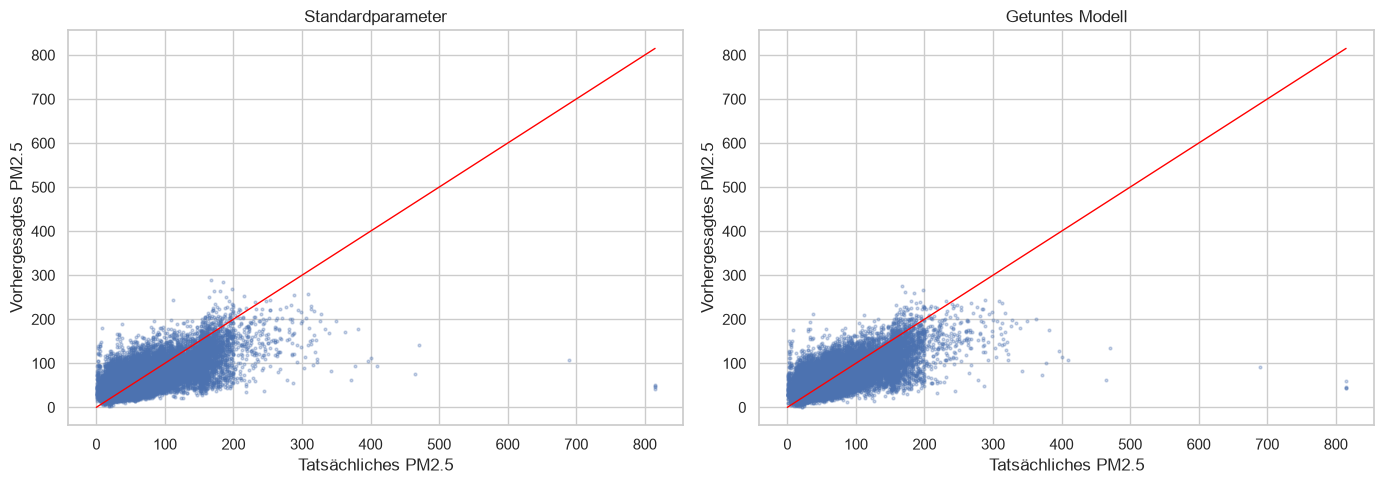

Gespeichert: models/gb_best_params_alle_features.json


In [10]:
bins = pd.cut(y, [0, 25, 50, 100, 150, 200, 1000])
err = pd.DataFrame({"bin": bins,
                    "MAE_Standard": np.abs(y - oof_default),
                    "MAE_Getunt": np.abs(y - oof_tuned),
                    "se_std": (y - oof_default) ** 2, "se_tuned": (y - oof_tuned) ** 2})
by_bin = err.groupby("bin", observed=True).agg(
    Zeilen=("MAE_Standard", "size"), MAE_Standard=("MAE_Standard", "mean"),
    MAE_Getunt=("MAE_Getunt", "mean"), SE_Std=("se_std", "sum"), SE_Tuned=("se_tuned", "sum"))
by_bin["Anteil Fehler Getunt"] = (by_bin["SE_Tuned"] / by_bin["SE_Tuned"].sum()).round(3)
display(by_bin.drop(columns=["SE_Std", "SE_Tuned"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in zip(axes, [oof_default, oof_tuned], ["Standardparameter", "Getuntes Modell"]):
    ax.scatter(y, pred, s=4, alpha=0.3)
    lim = [0, max(y.max(), pred.max())]
    ax.plot(lim, lim, color="red", lw=1)
    ax.set_xlabel("Tatsächliches PM2.5"); ax.set_ylabel("Vorhergesagtes PM2.5")
    ax.set_title(title)
plt.tight_layout()
plt.show()

Path("models").mkdir(exist_ok=True)
with open("models/gb_best_params_alle_features.json", "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=2)
print("Gespeichert: models/gb_best_params_alle_features.json")

## 7. Ergebnis und Vergleich mit dem ersten Durchlauf

**RMSE (5-fach GroupKFold nach Ort, 77 Features)**

| Modell | RMSE | Fold-Std | MAE | R² |
| --- | --- | --- | --- | --- |
| Standardparameter | 33,19 | 3,81 | 22,91 | 0,50 |
| Getunt, beste Konfiguration (optimistisch) | 32,10 | 3,77 | 21,85 | 0,53 |
| Getunt, verschachtelt (ehrlich) | 32,94 | 3,74 | 22,72 | 0,51 |

Zum Vergleich, erster Durchlauf mit den 8 Baseline-Features: 37,00, 36,92 (beste
Konfiguration) und 37,00 (verschachtelt).

**Beobachtungen**

- **Mehr Features bringen viel mehr als Tuning.** Der Wechsel von 8 auf 77
  Rohfeatures senkt den RMSE im Standardmodell von 37,0 auf 33,2. Das ist ein Gewinn von 3,8.
  Tuning ergibt dagegen nur 0,25 (verschachtelt) bis 1,09 (optimistisch).
- **Tuning hilft hier etwas mehr als bei 8 Features,** aber der ehrliche Wert ist klein.
  Die beste Konfiguration schlägt das Standardmodell in jedem der 5 Folds (um 1,0 bis 1,2),
  allerdings wurde sie auf genau diesen Folds ausgewählt. In der verschachtelten
  Validierung bleiben 0,25 RMSE, deutlich unter der Fold-Streuung von etwa 3,8.
- **Die Suche zeigt eine klare Richtung:** Je kleiner die Lernrate, desto besser
  (Spearman −0,57 mit dem RMSE). Dazu kommen größere Mindestblätter und
  `max_features` 0,7 (Regularisierung). Die besten drei Konfigurationen liegen
  eng beieinander (31,87 bis 31,95). Die Konfiguration der verschachtelten Suche
  war in allen Folds dieselbe, vermutlich weil die Suche bei gleichem
  Zufallsstartwert jeweils dieselben 10 Kandidaten testet. Sie ist daher weniger aussagekräftig als
  die 30er-Suche.
- **Die Geometrie-Spalten stecken im Standardmodell:** 35 der 77 Features
  stehen für 24 % der Permutation Importance. Das sind die verdeckten Ortskennungen
  aus der Auswertung der Sensorhöhe. Die Satellitenwerte und das Wetter liefern
  den Rest.
- **Spitzenwerte bleiben das Problem:** Bei Werten über 200 sinkt der MAE
  nur von 114,4 auf 110,0. Werte über 150 verursachen weiter etwa 42 % des
  quadratischen Fehlers.

**Schlussfolgerung**

Mit allen Rohfeatures liegt der Standardwert bei 33,2 und das getunte Modell
ehrlich bei 32,9. Das Feature Engineering (`lukas_feature_engineering_alle_features.ipynb`)
erreicht dagegen rund 30,2. Der Engpass liegt weiter bei den Features,
nicht bei den Modelleinstellungen. Eine Konfiguration mit kleiner Lernrate,
vielen Bäumen und starker Regularisierung ist ein vernünftiger Startpunkt für
eine Suche auf dem finalen Feature-Set (`models/gb_best_params_alle_features.json`).
